<a href="https://colab.research.google.com/github/ilamaalajmah/MNIST-NN-Classification/blob/main/Digit_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [81]:
# Import the required libraries
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Set the random seed to make experiments reproducible
keras.utils.set_random_seed(42)
print("TensorFlow/Keras version:", keras.__version__)

TensorFlow/Keras version: 3.13.2


In [82]:
# Load and split the MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [83]:
# Explore the dataset
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)
print(x_train.dtype) # Original data type (uint8) | 0-255
print("the min number is: ",x_train.min())
print("the max number is: ",x_train.max())

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)
uint8
the min number is:  0
the max number is:  255


In [84]:
# Display the unique digit classes in the training labels
print("the classification numbers", np.unique(y_train))

the classification numbers [0 1 2 3 4 5 6 7 8 9]


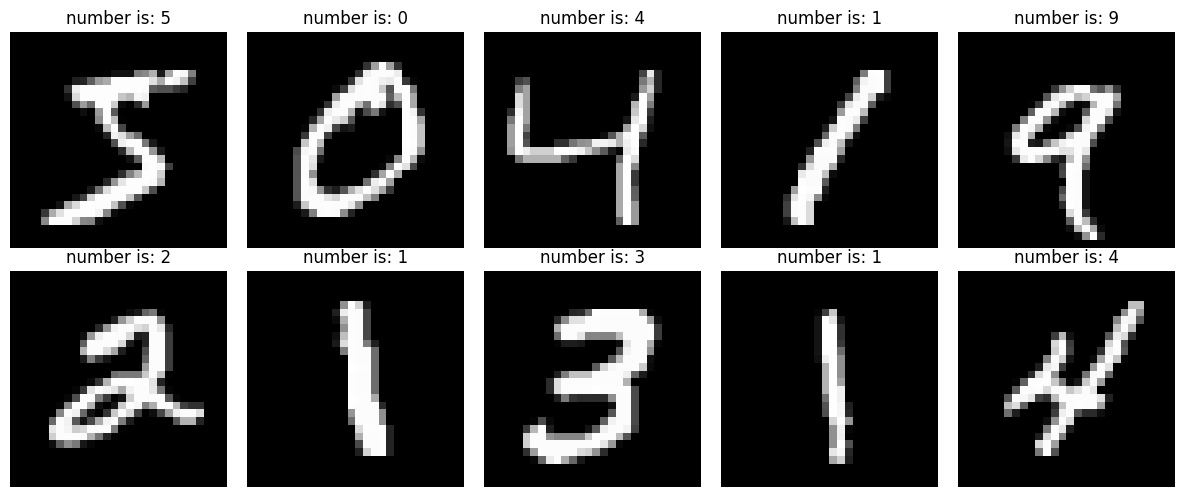

In [85]:
# Visualize the first 10 training images and their corresponding labels
plt.figure(figsize=(12,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"number is: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [86]:
# Normalize pixel values to range from 0-1
x_train = x_train.astype("float32")/255.0
x_test = x_test.astype("float32")/255.0
print(x_train.min())
print(x_train.max())
print(x_train.dtype)

0.0
1.0
float32


In [87]:
model = keras.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(10,activation="softmax"),
])

In [88]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [89]:
history = model.fit(
    x_train,y_train,
    batch_size=64,
    epochs=10,
    validation_split=0.2,
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9087 - loss: 0.3253 - val_accuracy: 0.9503 - val_loss: 0.1776
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9575 - loss: 0.1487 - val_accuracy: 0.9635 - val_loss: 0.1298
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9704 - loss: 0.1036 - val_accuracy: 0.9688 - val_loss: 0.1099
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9783 - loss: 0.0783 - val_accuracy: 0.9710 - val_loss: 0.0999
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9826 - loss: 0.0615 - val_accuracy: 0.9724 - val_loss: 0.0952
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9871 - loss: 0.0490 - val_accuracy: 0.9732 - val_loss: 0.0919
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9901 - loss: 0.0390 - val_accuracy: 0.9741 - val_loss: 0.0904
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9931 - loss: 0.0310 - val_accuracy: 0.

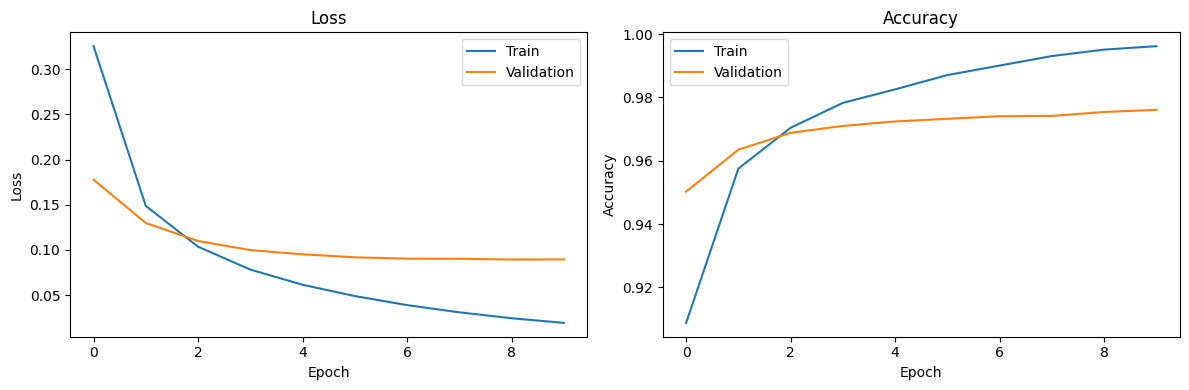

In [90]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2 , 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [91]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 0.9760


In [92]:
print(x_train.shape, x_test.shape)   # لازم: (60000, 28, 28) (10000, 28, 28)
print(x_train.max(), x_test.max())   # لازم: 1.0 1.0

(60000, 28, 28) (10000, 28, 28)
1.0 1.0


Output shape: (10, 10)
Predictions: [7 2 1 0 4 1 4 9 5 9]
True labels: [7 2 1 0 4 1 4 9 5 9]


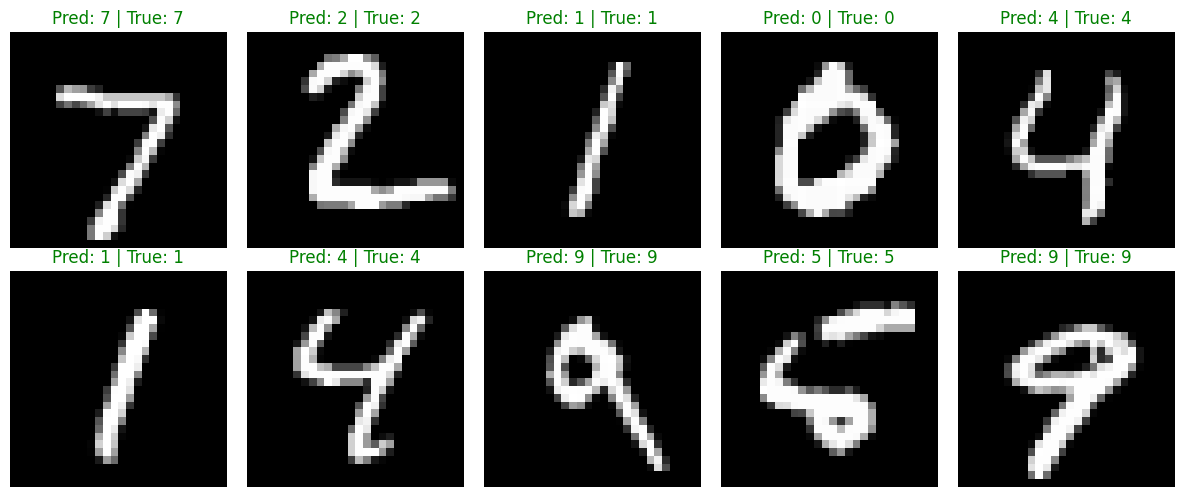

In [93]:
predictions = model.predict(x_test[:10], verbose=0)
predicted_digits = np.argmax(predictions, axis=1)

print("Output shape:", predictions.shape)
print("Predictions:", predicted_digits)
print("True labels:", y_test[:10])

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    color = "green" if predicted_digits[i] == y_test[i] else "red"
    plt.title(f"Pred: {predicted_digits[i]} | True: {y_test[i]}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

Number of errors: 246 out of 10000


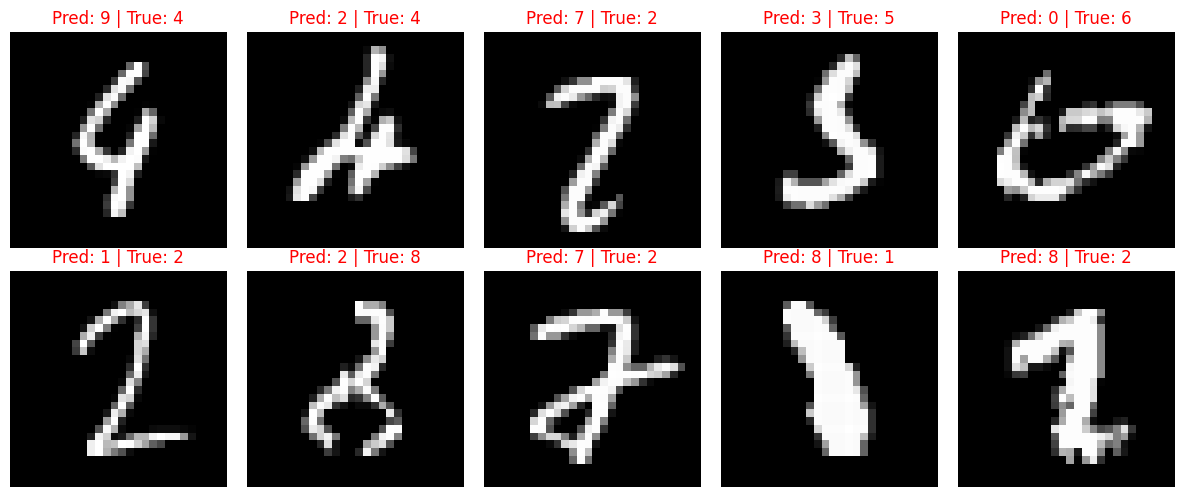

In [94]:
all_predictions = np.argmax(model.predict(x_test, verbose=0), axis=1)
wrong_idx = np.where(all_predictions != y_test)[0]

print("Number of errors:", len(wrong_idx), "out of", len(y_test))

plt.figure(figsize=(12, 5))
for k, idx in enumerate(wrong_idx[:10]):
    plt.subplot(2, 5, k + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(f"Pred: {all_predictions[idx]} | True: {y_test[idx]}", color="red")
    plt.axis("off")
plt.tight_layout()
plt.show()

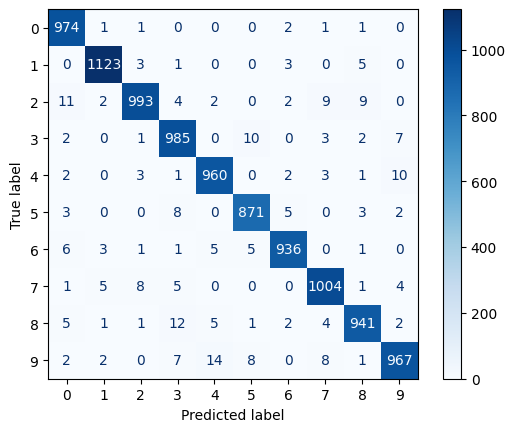

In [95]:
cm = confusion_matrix(y_test, all_predictions)
ConfusionMatrixDisplay(cm).plot(cmap="Blues", values_format="d")
plt.show()